# Heart rate estimation from PPG signal and finger video

## Importing raw data and plotting

fs = 30.0 Hz, duration = 30.4 s


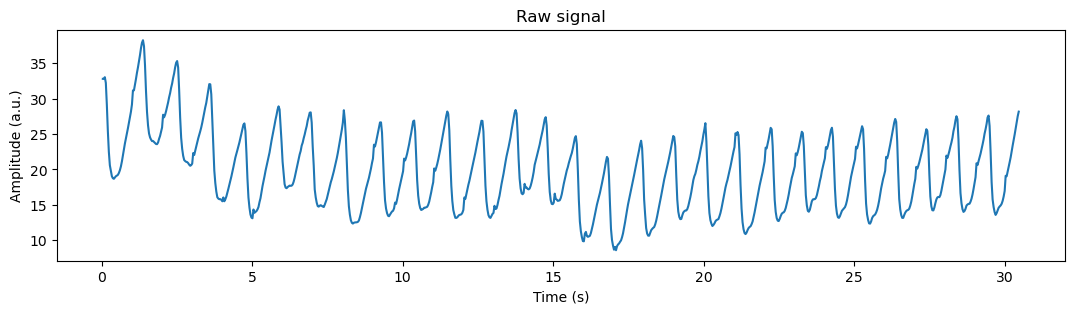

In [5]:
import numpy as np
import matplotlib.pyplot as plt

#pull in the data
data=np.genfromtxt("data/heart_beat_signal.csv", delimiter=",")

# assign values in the csv value to t and x
t, x = data[:, 0], data[:, 1]

#finding the sampling frequency (Hz) (1/ average time between samples)
fs = 1 / np.mean(np.diff(t))

#output the sampling frequency and duration of signal
print(f"fs = {fs:.1f} Hz, duration = {t[-1]-t[0]:.1f} s")

#plotting raw signal graph:
plt.figure(figsize=(13, 3))
plt.plot(t, x)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")

plt.title("Raw signal")
plt.savefig("figures/raw_signal.png")
plt.show()

## Filtering

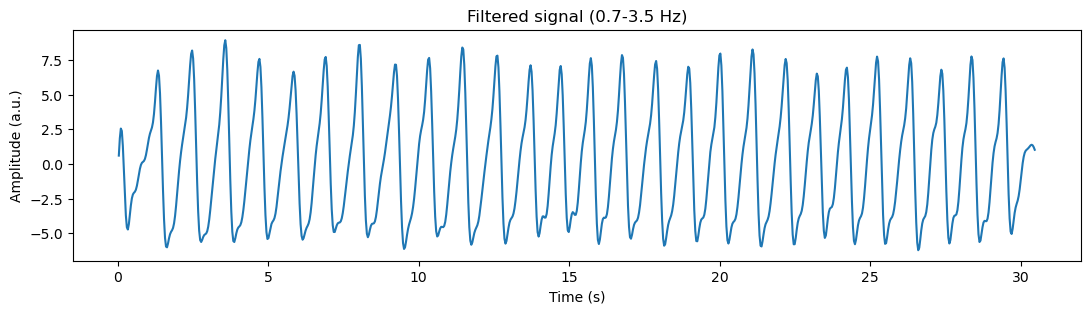

In [ ]:
from scipy.signal import butter, filtfilt, detrend

#designing a bandpass filter (LPF reduces high frequency noise, HPF removes low frequency drift)
# 0.7 Hz is the lower cutoff frequency, 3.5 Hz is the upper cutoff frequency, and fs is the sampling frequency
# -> these frequencies were chosen based on expected heart rate.
b, a = butter(4, [0.7, 3.5], btype="band", fs=fs)

#applying the filter to the signal
x_filt = filtfilt(b,a,x)

#plotting filtered signal graph
plt.figure(figsize=(13, 3))
plt.plot(t, x_filt)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.title("Filtered signal (0.7-3.5 Hz)")
plt.savefig("figures/filtered_signal.png")
plt.show()
